Connected to Python 3.13.0

In [ ]:
import os
import sys
import numpy as np
import anndata as ad
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

# Add current directory to path for imports
current_dir = os.path.dirname(os.path.abspath(__file__))
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

# Import visualization functions
import importlib
import visualization_functions

importlib.reload(visualization_functions)  # Force reload to avoid cache issues

from visualization_functions import (
    plot_stacked_bar_by_odt,
    plot_violin_stripplot_by_group,
    plot_scatter_comparison_m9f_m9,
)

In [ ]:
# Set working directory
os.chdir(os.path.dirname(os.path.dirname(os.path.dirname(os.path.abspath(__file__)))))

In [ ]:
# Load the filtered data from 3a
print("📂 Loading filtered data from 3a...")
INPUT_PATH = "data/Anndata/filtered"
INPUT_FILE = "GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI.h5ad"

# Load the filtered data
adata_raw_filtered_100UMI = ad.read_h5ad(os.path.join(INPUT_PATH, INPUT_FILE))

print(
    f"📊 Loaded dataset: {adata_raw_filtered_100UMI.n_obs:,} cells × {adata_raw_filtered_100UMI.n_vars:,} genes"
)
print(f"🔢 Available obs columns: {list(adata_raw_filtered_100UMI.obs.columns)}")

📂 Loading filtered data from 3a...
📊 Loaded dataset: 132,233 cells × 6,248 genes
🔢 Available obs columns: ['barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_counts', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'group']



📊 STEP 1: INITIAL DATASET VISUALIZATIONS
🧮 Ensuring n_counts is properly calculated...
✅ n_counts column already exists

📊 1.1 Generating stacked bar plot...


/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:270: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(["group", "RepBio", "RepTech_suffix"])
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:405: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("CultureMedium")


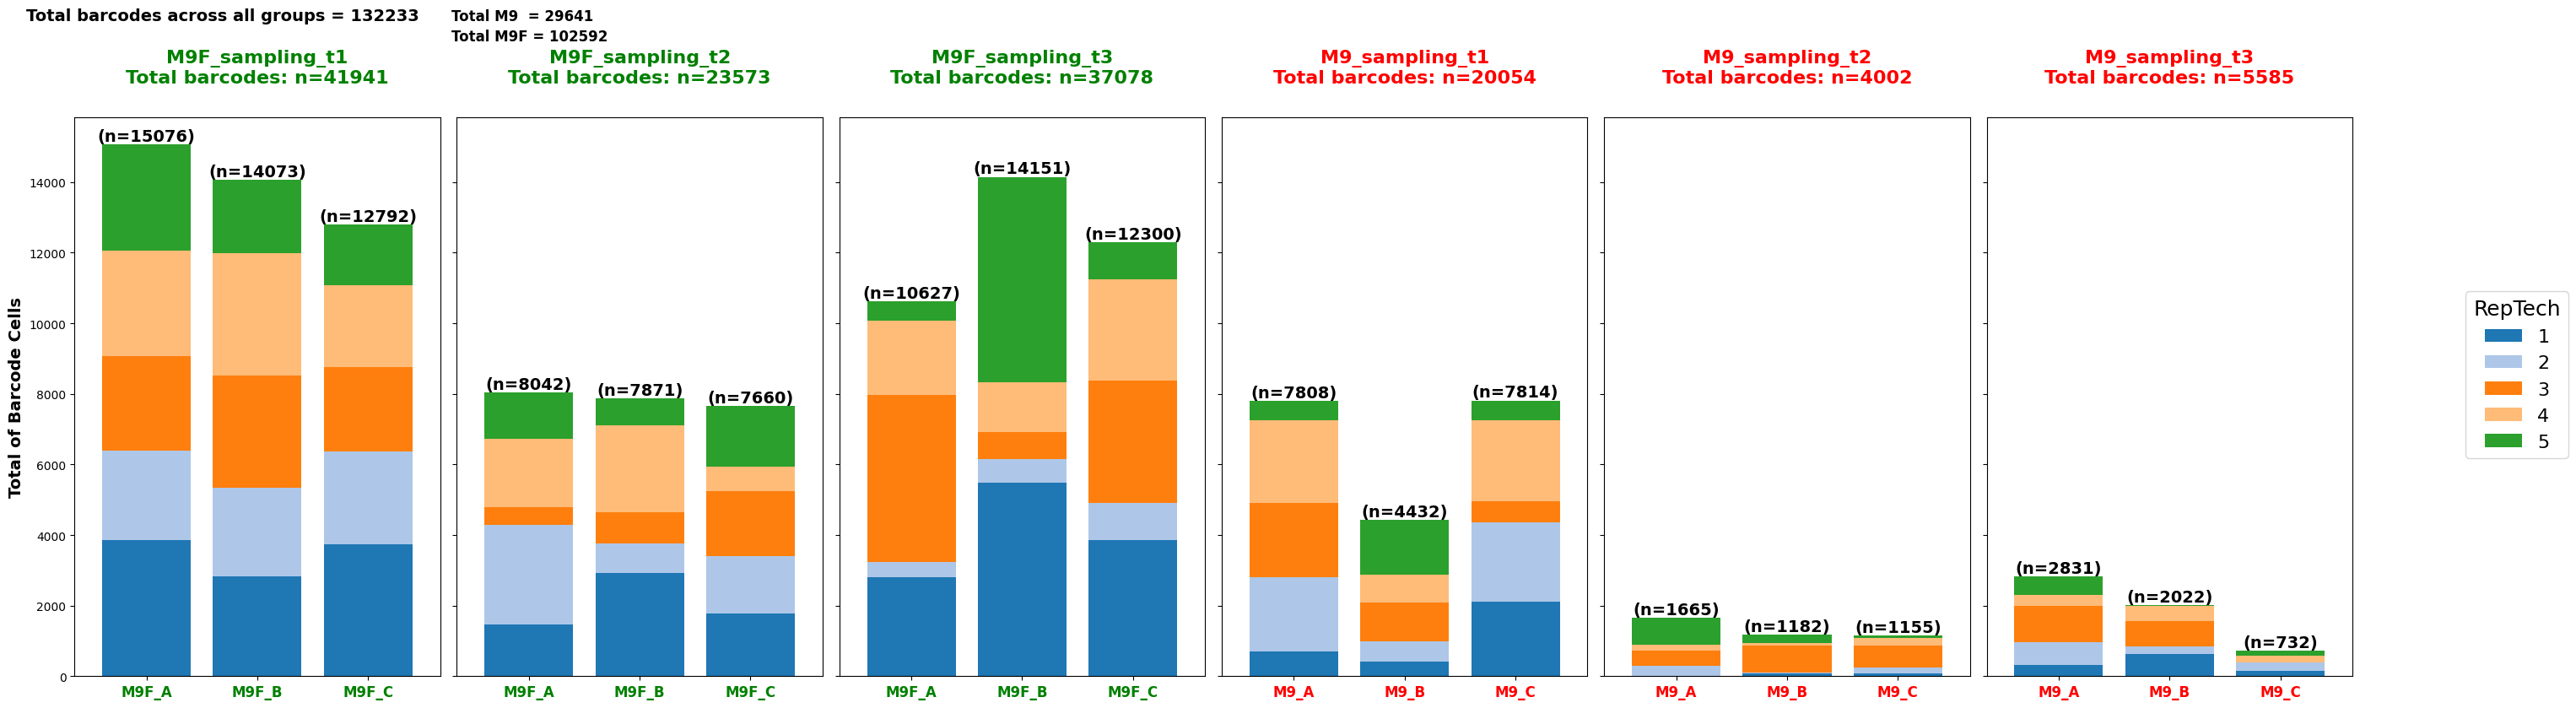

📊 Total cells: 132,233

📊 1.2 Generating violin + stripplot...


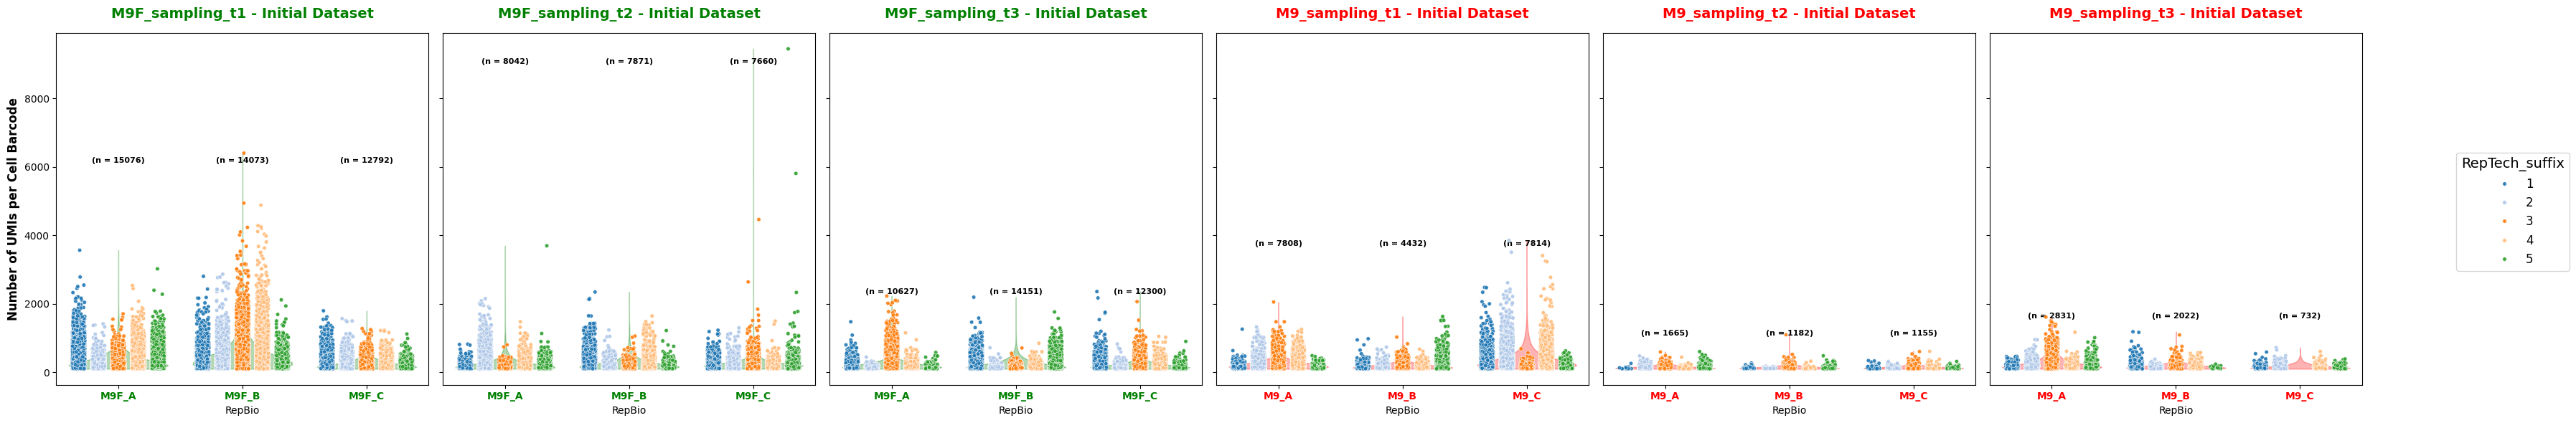

In [ ]:
# STEP 1: Initial dataset visualizations
print("\n" + "=" * 80)
print("📊 STEP 1: INITIAL DATASET VISUALIZATIONS")
print("=" * 80)

# Ensure n_counts is properly calculated
print("🧮 Ensuring n_counts is properly calculated...")
if "n_counts" not in adata_raw_filtered_100UMI.obs.columns:
    print("⚠️  n_counts column not found, calculating...")
    if hasattr(adata_raw_filtered_100UMI.X, "toarray"):
        adata_raw_filtered_100UMI.obs["n_counts"] = np.array(
            adata_raw_filtered_100UMI.X.sum(axis=1)
        ).flatten()
    else:
        adata_raw_filtered_100UMI.obs["n_counts"] = adata_raw_filtered_100UMI.X.sum(
            axis=1
        )
else:
    print("✅ n_counts column already exists")

# Add RepTech_suffix if not present
if "RepTech_suffix" not in adata_raw_filtered_100UMI.obs.columns:
    adata_raw_filtered_100UMI.obs["RepTech_suffix"] = (
        adata_raw_filtered_100UMI.obs["RepTech"].str.split("_").str[-1]
    )

# Stacked bar plot
print("\n📊 1.1 Generating stacked bar plot...")
total_all, total_by_medium = plot_stacked_bar_by_odt(adata_raw_filtered_100UMI)
print(f"📊 Total cells: {total_all:,}")

# Violin + stripplot
print("\n📊 1.2 Generating violin + stripplot...")
plot_violin_stripplot_by_group(
    adata=adata_raw_filtered_100UMI,
    y_column="n_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - Initial Dataset",
    figsize_per_plot=6,
)

In [ ]:
def select_cells_by_group(
    adata: ad.AnnData,
    target_total_cells: int,
    group_by: str = "OD",
    sort_by: str = "n_counts",
    random: bool = False,
    seed: int = None,
    descending: bool = True,
) -> dict:
    """
    Select cells by group with balanced sampling.
    """
    meta = adata.obs.copy()
    meta["cell_barcode"] = meta.index

    # Input validation
    if group_by not in meta.columns:
        raise ValueError(f"Group column '{group_by}' not found in adata.obs.")
    if sort_by not in meta.columns:
        raise ValueError(f"Sort column '{sort_by}' not found in adata.obs.")

    n_groups = meta[group_by].nunique()
    target_per_group = target_total_cells // n_groups

    print(f"🎯 Target total cells: {target_total_cells:,}")
    print(f"📁 Group column: '{group_by}' — {n_groups} groups")
    print(f"🧮 Sort by: '{sort_by}' | Descending: {descending}")
    print(f"🔢 Cells per group: {target_per_group:,}")

    selected_cells = []
    selection_summary = []

    for group, df_group in meta.groupby(group_by):
        n_available = len(df_group)
        print(f"\n🔍 Group '{group}': {n_available:,} cells available")

        if n_available <= target_per_group:
            print(f"✅ Keeping all {n_available:,} cells")
            selected = df_group["cell_barcode"].tolist()
            n_selected = n_available
        else:
            if random:
                if seed is not None:
                    np.random.seed(seed)
                selected = df_group.sample(n=target_per_group, random_state=seed)[
                    "cell_barcode"
                ].tolist()
            else:
                df_sorted = df_group.sort_values(by=sort_by, ascending=not descending)
                selected = df_sorted.head(target_per_group)["cell_barcode"].tolist()
            n_selected = target_per_group
            print(f"📊 Selected {n_selected:,} cells from {n_available:,}")

        selected_cells.extend(selected)
        selection_summary.append(
            {
                "group": group,
                "available": n_available,
                "selected": n_selected,
                "percentage": (n_selected / n_available) * 100,
            }
        )

    adata_filtered = adata[selected_cells].copy()
    summary_df = pd.DataFrame(selection_summary)

    print(f"\n📊 Selection summary:")
    print(f"   Total cells selected: {len(selected_cells):,}")
    print(f"   Target was: {target_total_cells:,}")

    return {
        "adata": adata_filtered,
        "summary": summary_df,
        "selected_cells": selected_cells,
    }


📊 STEP 2: BALANCED SUBSAMPLING TO 4000 CELLS
🎯 Target total cells: 4,000
📁 Group column: 'OD' — 18 groups
🧮 Sort by: 'n_counts' | Descending: True
🔢 Cells per group: 222

🔍 Group 'M9F_A_OD1': 15,076 cells available
📊 Selected 222 cells from 15,076

🔍 Group 'M9F_A_OD2': 8,042 cells available
📊 Selected 222 cells from 8,042

🔍 Group 'M9F_A_OD3': 10,627 cells available
📊 Selected 222 cells from 10,627

🔍 Group 'M9F_B_OD1': 14,073 cells available
📊 Selected 222 cells from 14,073

🔍 Group 'M9F_B_OD2': 7,871 cells available
📊 Selected 222 cells from 7,871

🔍 Group 'M9F_B_OD3': 14,151 cells available
📊 Selected 222 cells from 14,151

🔍 Group 'M9F_C_OD1': 12,792 cells available
📊 Selected 222 cells from 12,792

🔍 Group 'M9F_C_OD2': 7,660 cells available
📊 Selected 222 cells from 7,660

🔍 Group 'M9F_C_OD3': 12,300 cells available
📊 Selected 222 cells from 12,300

🔍 Group 'M9_A_OD1': 7,808 cells available
📊 Selected 222 cells from 7,808

🔍 Group 'M9_A_OD2': 1,665 cells available
📊 Selected 222 

<ipython-input-5-60bc73d00f31>:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group, df_group in meta.groupby(group_by):
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:270: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(["group", "RepBio", "RepTech_suffix"])
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:405: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observe

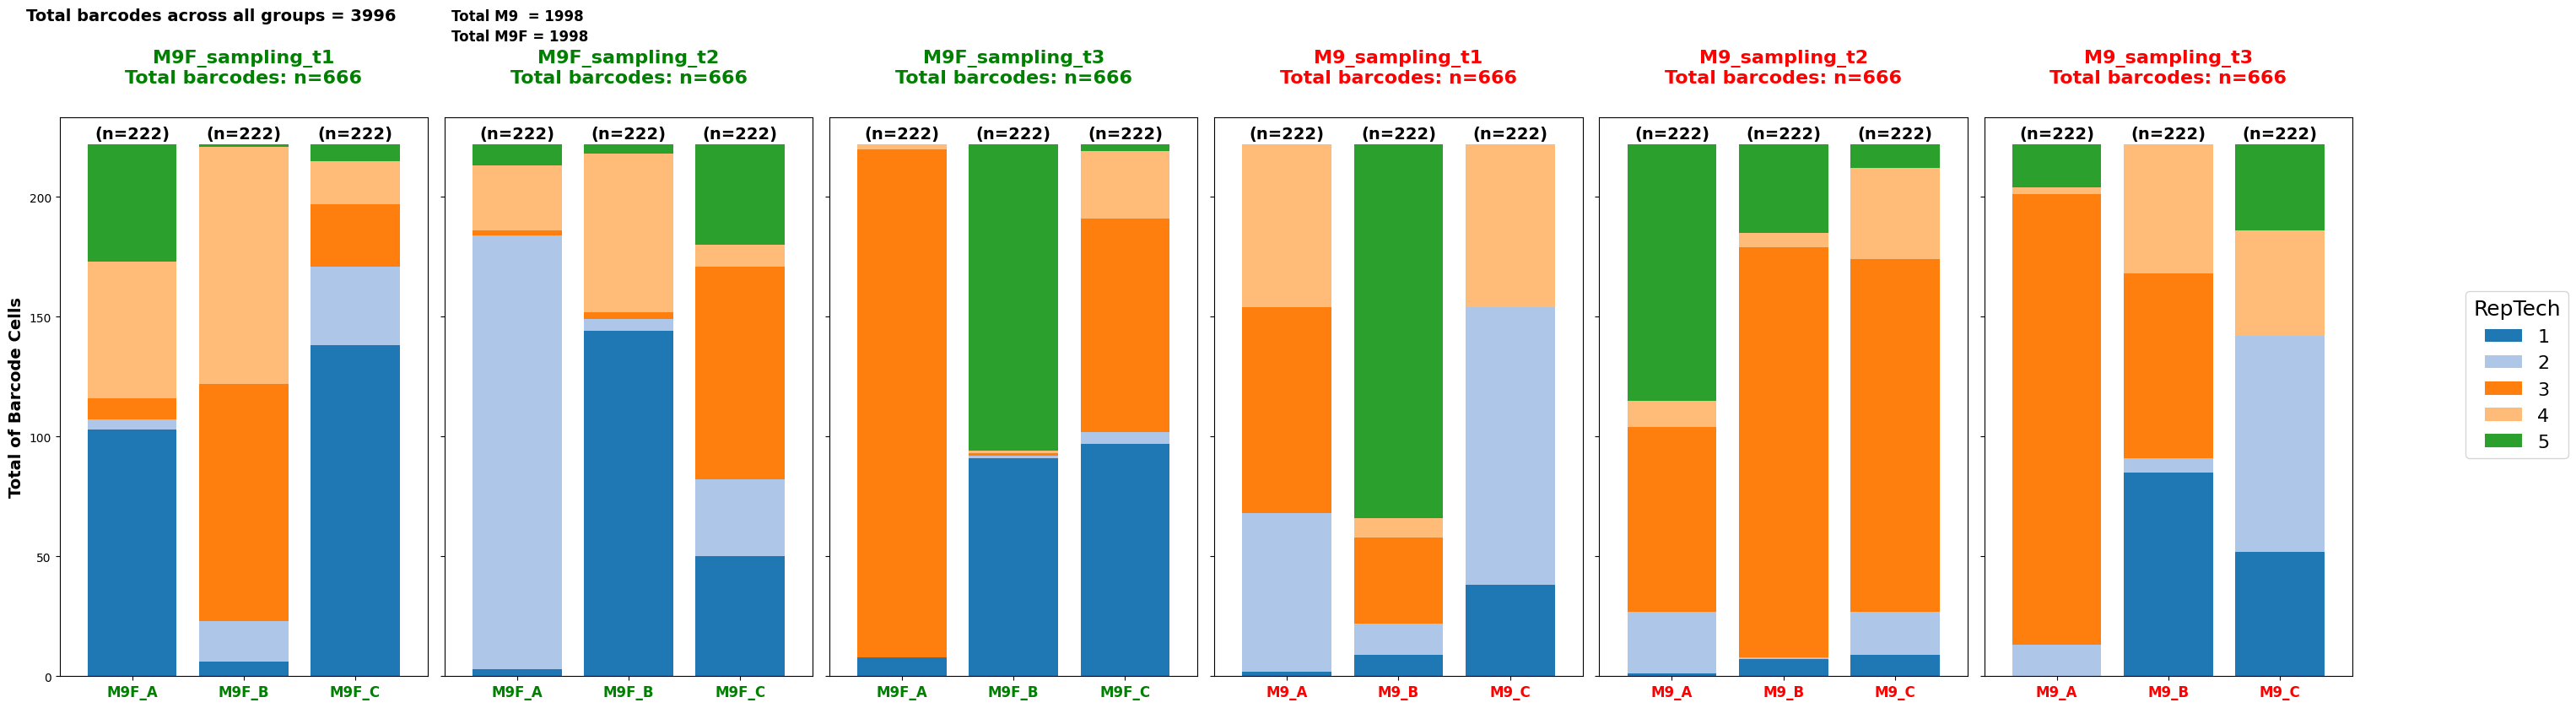

📊 Total cells: 3,996

📊 2.2 Generating violin + stripplot...


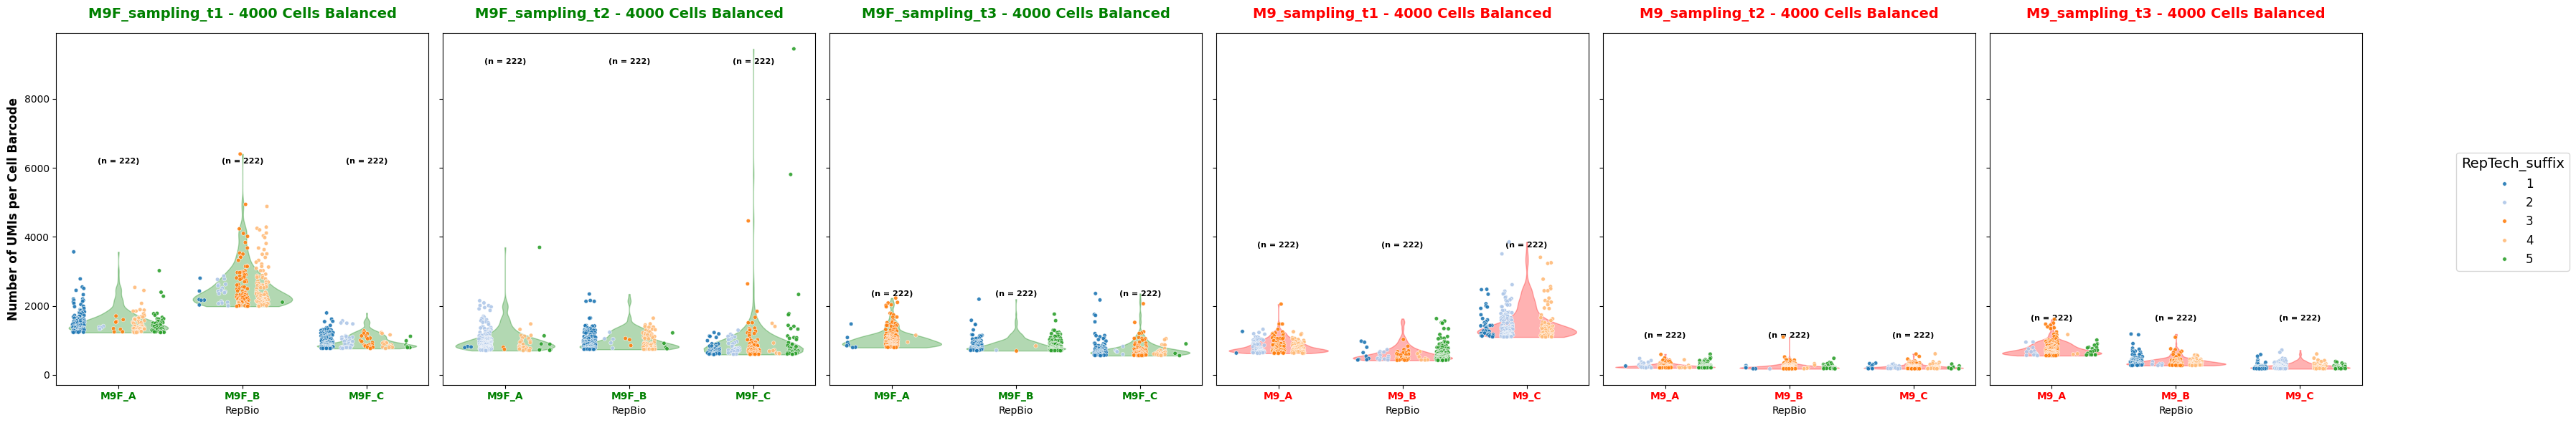

In [ ]:
# STEP 2: Balanced subsampling to 4000 cells
print("\n" + "=" * 80)
print("📊 STEP 2: BALANCED SUBSAMPLING TO 4000 CELLS")
print("=" * 80)

TARGET_CELLS_4000 = 4000

result = select_cells_by_group(
    adata=adata_raw_filtered_100UMI,
    target_total_cells=TARGET_CELLS_4000,
    group_by="OD",
    sort_by="n_counts",
    random=False,
    seed=42,
    descending=True,
)

adata_filtered_100UMI_balanced_4000cells_by_OD = result["adata"]
print(f"✅ Subsampling to 4000 cells completed!")

# Stacked bar plot
print("\n📊 2.1 Generating stacked bar plot...")
total_all, total_by_medium = plot_stacked_bar_by_odt(
    adata_filtered_100UMI_balanced_4000cells_by_OD
)
print(f"📊 Total cells: {total_all:,}")

# Violin + stripplot
print("\n📊 2.2 Generating violin + stripplot...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_100UMI_balanced_4000cells_by_OD,
    y_column="n_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - 4000 Cells Balanced",
    figsize_per_plot=6,
)

In [ ]:
def remove_outliers_by_reptech(
    adata: ad.AnnData,
    outlier_groups: dict,
    sort_by: str = "n_counts",
    descending: bool = True,
) -> ad.AnnData:
    """
    Remove outlier cells from specific RepTech groups.
    """
    print(f"📊 Starting outlier removal by RepTech...")
    print(f"📊 Initial dataset: {adata.n_obs:,} cells")

    if sort_by not in adata.obs.columns:
        raise ValueError(f"Sort column '{sort_by}' not found in adata.obs")

    cells_to_remove = []
    removal_summary = []

    for reptech, n_cells in outlier_groups.items():
        if reptech not in adata.obs["RepTech"].values:
            print(f"⚠️  Warning: RepTech '{reptech}' not found in data")
            continue

        group_mask = adata.obs["RepTech"] == reptech
        n_available = sum(group_mask)

        if n_available == 0:
            print(f"⚠️  Warning: No cells found for RepTech '{reptech}'")
            continue

        if n_cells > n_available:
            print(
                f"⚠️  Warning: Cannot remove {n_cells} cells from '{reptech}' (only {n_available} available)"
            )
            n_cells = n_available

        highest_cells = adata.obs[group_mask][sort_by].nlargest(n_cells)

        print(
            f"🔍 RepTech '{reptech}': removing {n_cells} cells from {n_available} available"
        )
        for i, (idx, value) in enumerate(highest_cells.items(), 1):
            print(f"   {i}. Cell {idx}: {value:,} {sort_by}")

        cells_to_remove.extend(highest_cells.index.tolist())
        removal_summary.append(
            {
                "RepTech": reptech,
                "available": n_available,
                "removed": n_cells,
                "remaining": n_available - n_cells,
            }
        )

    cells_to_remove = list(set(cells_to_remove))
    print(f"\n🗑️ Total cells to remove: {len(cells_to_remove)}")

    cells_to_keep = ~adata.obs.index.isin(cells_to_remove)
    adata_filtered = adata[cells_to_keep].copy()

    print(f"📊 After outlier removal: {adata_filtered.n_obs:,} cells")
    print(f"🗑️ Total removed: {len(cells_to_remove)} cells")

    return adata_filtered


📊 STEP 3: REPTECH FILTERING (MIN 20 CELLS PER REPTECH)
🔧 Filtering RepTech groups with less than 20 cells...
📊 Before RepTech filtering: 3,996 cells
📊 RepTech groups with ≥20 cells: 45
📊 RepTech groups to remove: 37
📊 After RepTech filtering: 3,743 cells

📊 3.1 Generating stacked bar plot...


/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:270: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(["group", "RepBio", "RepTech_suffix"])
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:405: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("CultureMedium")


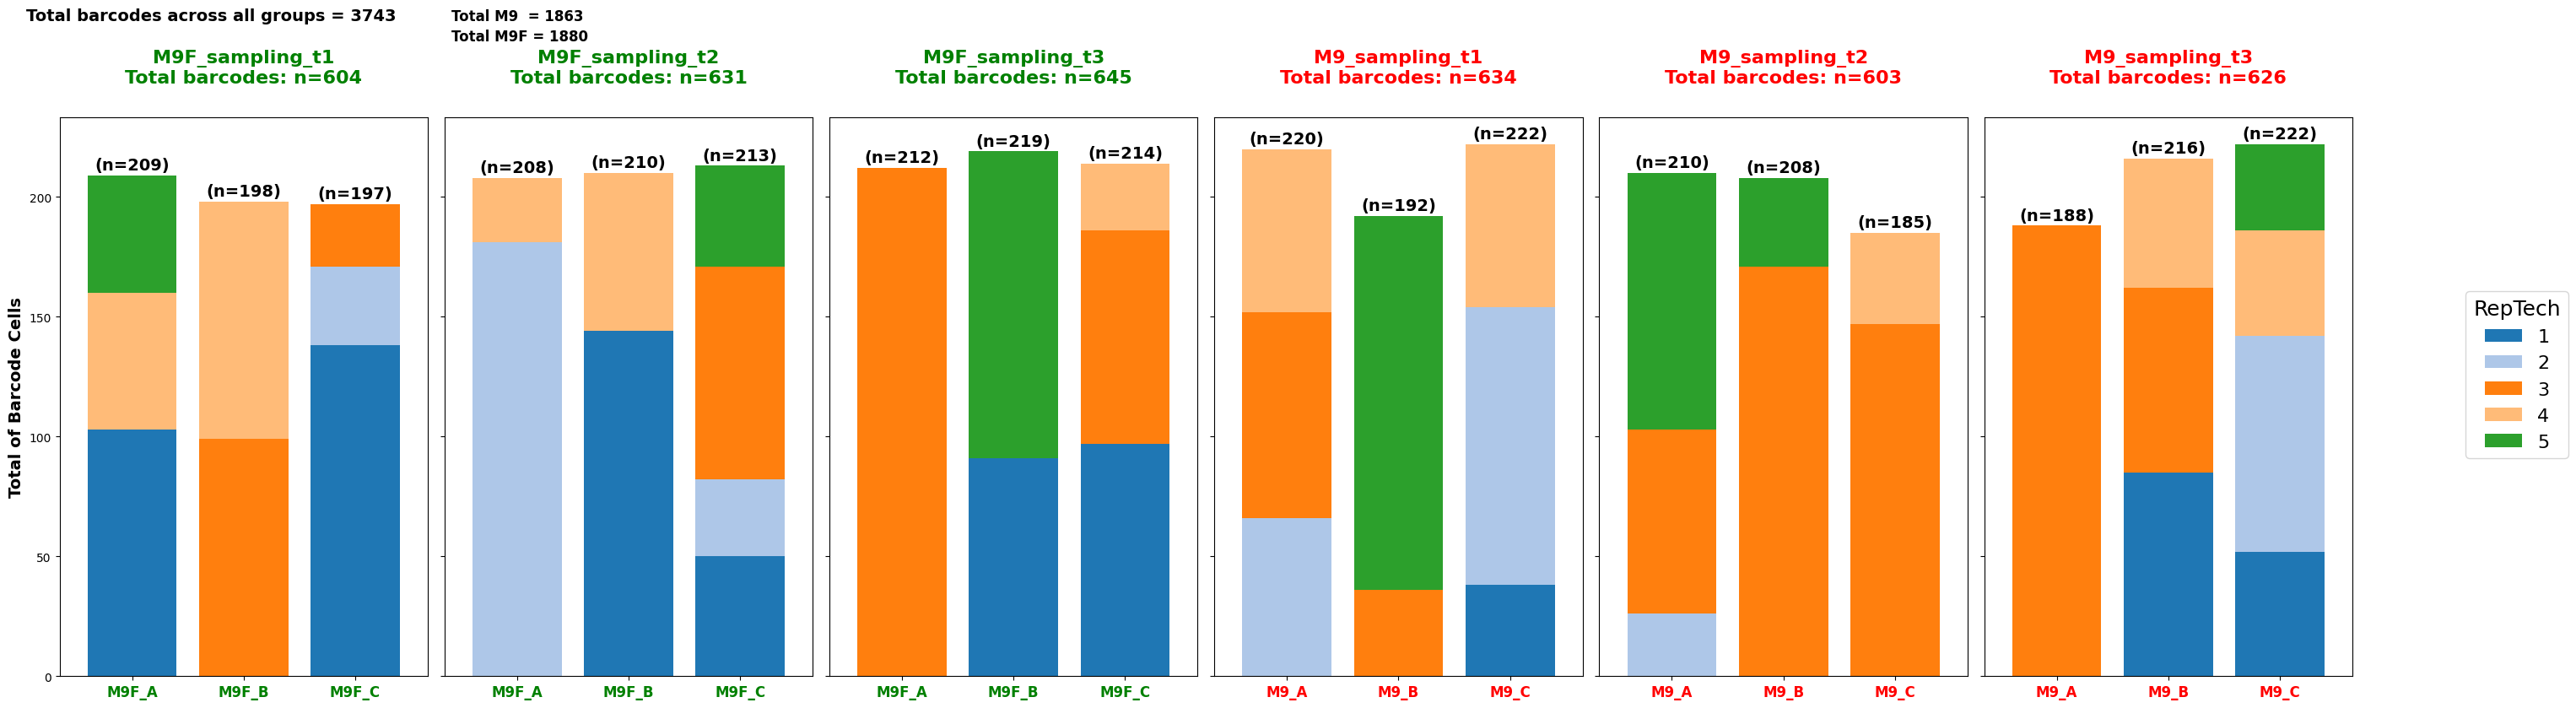

📊 Total cells: 3,743

📊 3.2 Generating violin + stripplot...


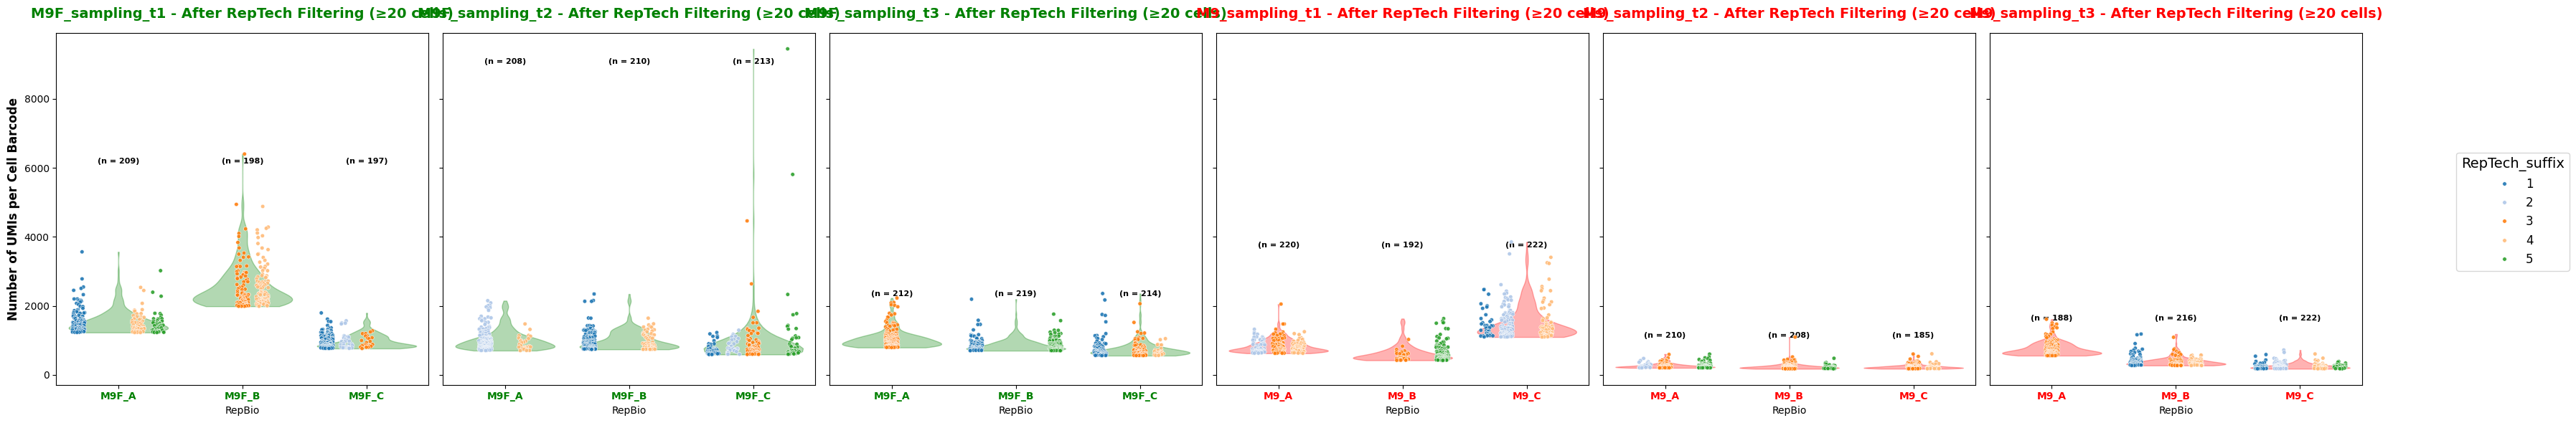

In [ ]:
# STEP 3: RepTech filtering (min 20 cells per RepTech)
print("\n" + "=" * 80)
print("📊 STEP 3: REPTECH FILTERING (MIN 20 CELLS PER REPTECH)")
print("=" * 80)

print("🔧 Filtering RepTech groups with less than 20 cells...")
print(
    f"📊 Before RepTech filtering: {adata_filtered_100UMI_balanced_4000cells_by_OD.n_obs:,} cells"
)

# Get RepTech groups with at least 20 cells
reptech_counts = adata_filtered_100UMI_balanced_4000cells_by_OD.obs[
    "RepTech"
].value_counts()
reptech_to_keep = reptech_counts[reptech_counts >= 20].index

print(f"📊 RepTech groups with ≥20 cells: {len(reptech_to_keep)}")
print(f"📊 RepTech groups to remove: {len(reptech_counts) - len(reptech_to_keep)}")

# Apply RepTech filtering
adata_filtered_100UMI_balanced_min20cells_per_RepTech = (
    adata_filtered_100UMI_balanced_4000cells_by_OD[
        adata_filtered_100UMI_balanced_4000cells_by_OD.obs["RepTech"].isin(
            reptech_to_keep
        )
    ].copy()
)

print(
    f"📊 After RepTech filtering: {adata_filtered_100UMI_balanced_min20cells_per_RepTech.n_obs:,} cells"
)

# Stacked bar plot
print("\n📊 3.1 Generating stacked bar plot...")
total_all, total_by_medium = plot_stacked_bar_by_odt(
    adata_filtered_100UMI_balanced_min20cells_per_RepTech
)
print(f"📊 Total cells: {total_all:,}")

# Violin + stripplot
print("\n📊 3.2 Generating violin + stripplot...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_100UMI_balanced_min20cells_per_RepTech,
    y_column="n_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - After RepTech Filtering (≥20 cells)",
    figsize_per_plot=6,
)


📊 STEP 4: REPTECH OUTLIER REMOVAL
📊 Current RepTech distribution:
RepTech
M9F_A_OD1_1    103
M9F_A_OD1_4     57
M9F_A_OD1_5     49
M9F_A_OD2_2    181
M9F_A_OD2_4     27
M9F_A_OD3_3    212
M9F_B_OD1_3     99
M9F_B_OD1_4     99
M9F_B_OD2_1    144
M9F_B_OD2_4     66
M9F_B_OD3_1     91
M9F_B_OD3_5    128
M9F_C_OD1_1    138
M9F_C_OD1_2     33
M9F_C_OD1_3     26
M9F_C_OD2_1     50
M9F_C_OD2_2     32
M9F_C_OD2_3     89
M9F_C_OD2_5     42
M9F_C_OD3_1     97
M9F_C_OD3_3     89
M9F_C_OD3_4     28
M9_A_OD1_2      66
M9_A_OD1_3      86
M9_A_OD1_4      68
M9_A_OD2_2      26
M9_A_OD2_3      77
M9_A_OD2_5     107
M9_A_OD3_3     188
M9_B_OD1_3      36
M9_B_OD1_5     156
M9_B_OD2_3     171
M9_B_OD2_5      37
M9_B_OD3_1      85
M9_B_OD3_3      77
M9_B_OD3_4      54
M9_C_OD1_1      38
M9_C_OD1_2     116
M9_C_OD1_4      68
M9_C_OD2_3     147
M9_C_OD2_4      38
M9_C_OD3_1      52
M9_C_OD3_2      90
M9_C_OD3_4      44
M9_C_OD3_5      36
Name: count, dtype: int64

⚠️  You need to analyze the violin plots ab

/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:270: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(["group", "RepBio", "RepTech_suffix"])
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:405: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("CultureMedium")


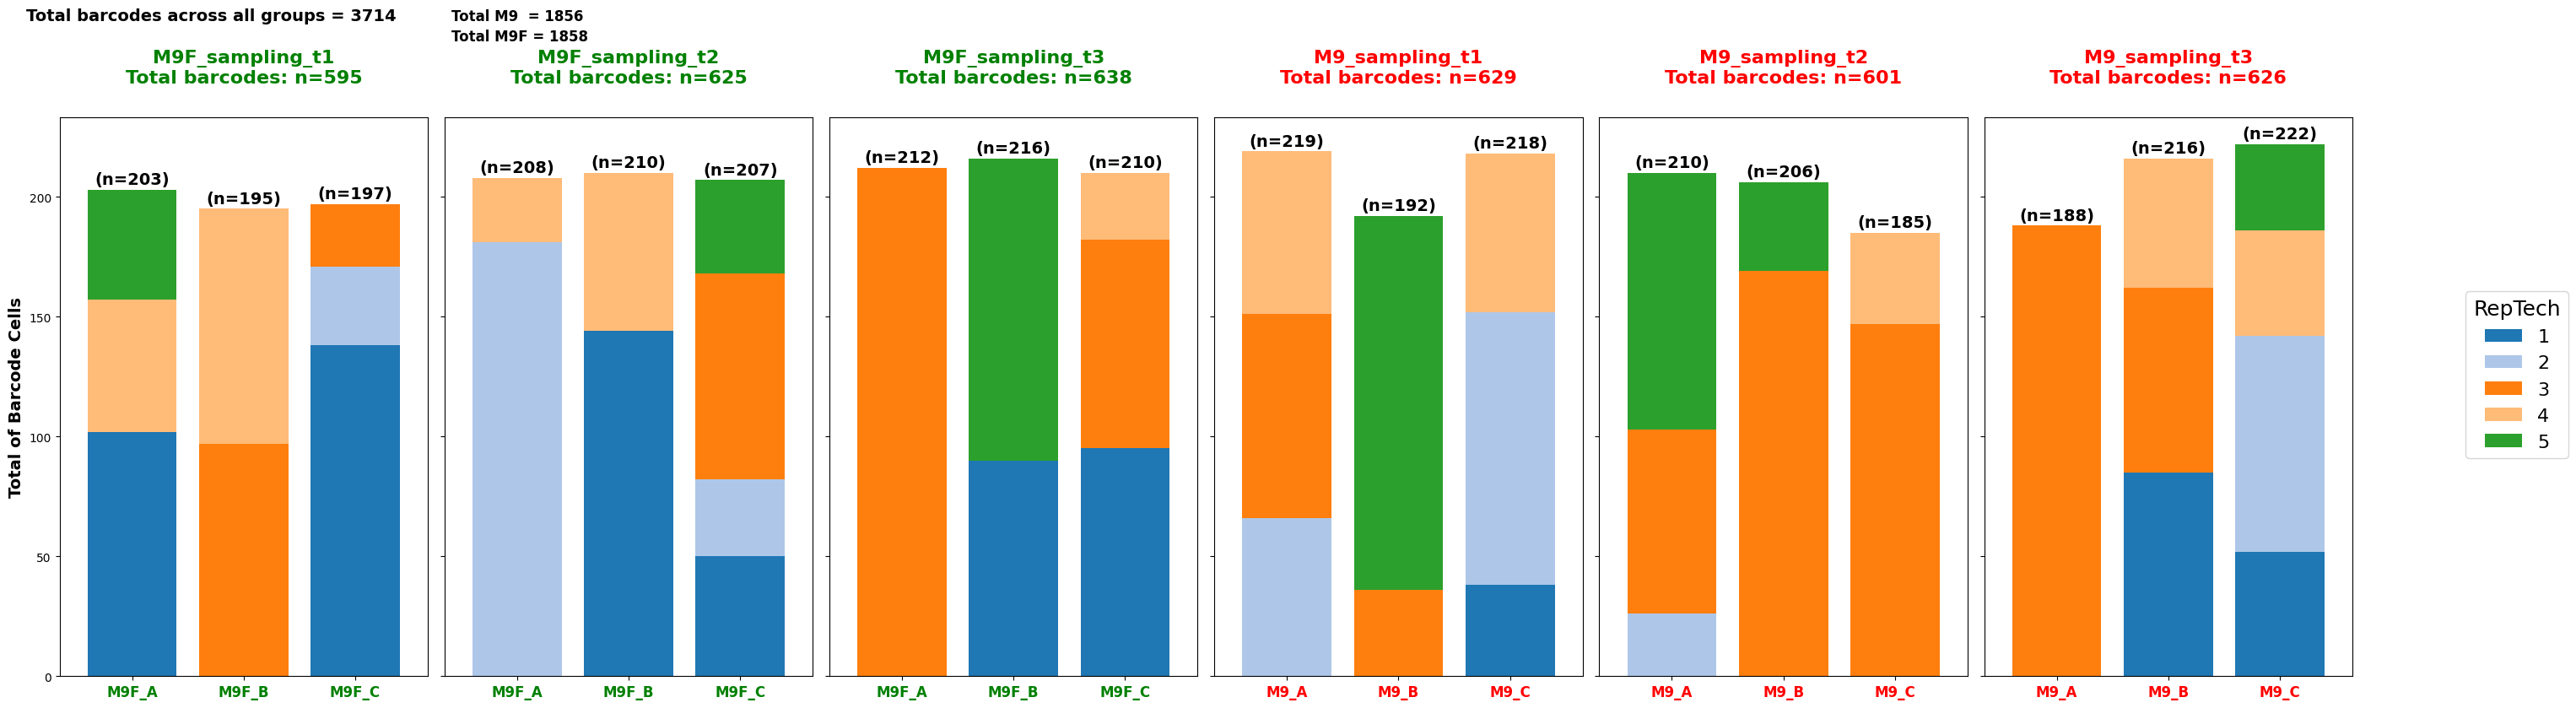

📊 Total cells: 3,714

📊 4.2 Generating violin + stripplot...


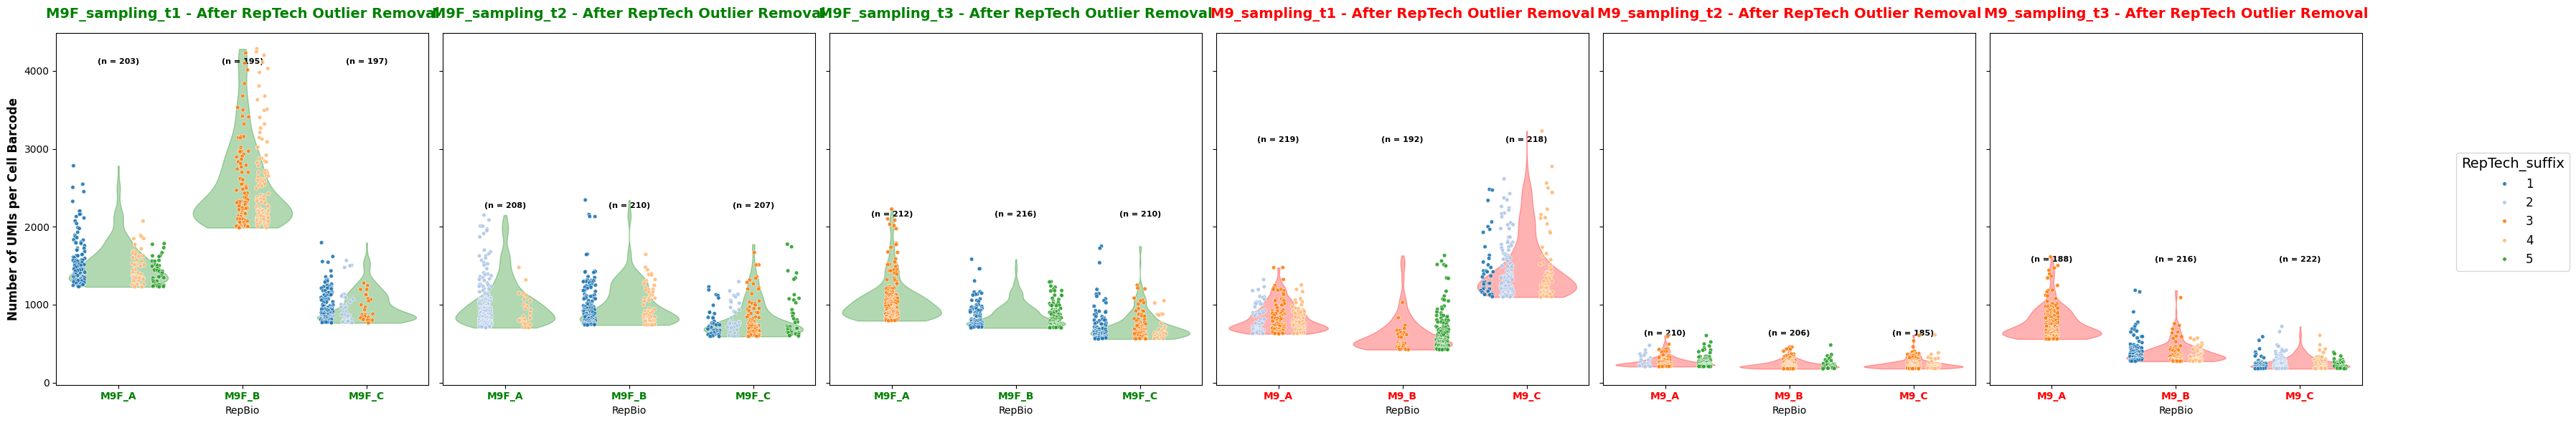

In [ ]:
# STEP 4: RepTech outlier removal (user will choose the points to filter)
print("\n" + "=" * 80)
print("📊 STEP 4: REPTECH OUTLIER REMOVAL")
print("=" * 80)

print("📊 Current RepTech distribution:")
reptech_counts = (
    adata_filtered_100UMI_balanced_min20cells_per_RepTech.obs["RepTech"]
    .value_counts()
    .sort_index()
)
print(reptech_counts)

print(
    "\n⚠️  You need to analyze the violin plots above and define OUTLIER_GROUPS_V2 dictionary."
)
print("💡 Example format:")
print("OUTLIER_GROUPS_V2 = {")
print("    'M9F_A_OD1_1': 1,")
print("    'M9_A_OD2_3': 2,")
print("    # Add more as needed...")
print("}")

# Define your outlier groups here (to be filled by user)
OUTLIER_GROUPS_V2 = {
    # User will define these based on the violin plots
    "M9F_A_OD1_1": 1,
    "M9F_A_OD1_4": 2,
    "M9F_A_OD1_5": 3,
    "M9F_B_OD1_3": 2,
    "M9F_B_OD1_4": 1,
    "M9F_C_OD2_3": 3,
    "M9F_C_OD2_5": 3,
    "M9F_B_OD3_1": 1,
    "M9F_B_OD3_5": 2,
    "M9F_C_OD3_1": 2,
    "M9F_C_OD3_3": 2,
    "M9_A_OD1_3": 1,
    "M9_C_OD1_2": 2,
    "M9_C_OD1_4": 2,
    "M9_B_OD2_3": 2,
}

if OUTLIER_GROUPS_V2:
    adata_filtered_100UMI_balanced_no_reptech_outliers = remove_outliers_by_reptech(
        adata_filtered_100UMI_balanced_min20cells_per_RepTech, OUTLIER_GROUPS_V2
    )
else:
    print("⚠️  No outlier groups defined. Skipping outlier removal.")
    adata_filtered_100UMI_balanced_no_reptech_outliers = (
        adata_filtered_100UMI_balanced_min20cells_per_RepTech.copy()
    )

# Stacked bar plot
print("\n📊 4.1 Generating stacked bar plot...")
total_all, total_by_medium = plot_stacked_bar_by_odt(
    adata_filtered_100UMI_balanced_no_reptech_outliers
)
print(f"📊 Total cells: {total_all:,}")

# Violin + stripplot
print("\n📊 4.2 Generating violin + stripplot...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_100UMI_balanced_no_reptech_outliers,
    y_column="n_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - After RepTech Outlier Removal",
    figsize_per_plot=6,
)


📊 STEP 5: BALANCED SUBSAMPLING TO 3000 CELLS
🎯 Target total cells: 3,000
📁 Group column: 'OD' — 18 groups
🧮 Sort by: 'n_counts' | Descending: True
🔢 Cells per group: 166

🔍 Group 'M9F_A_OD1': 203 cells available
📊 Selected 166 cells from 203

🔍 Group 'M9F_A_OD2': 208 cells available
📊 Selected 166 cells from 208

🔍 Group 'M9F_A_OD3': 212 cells available
📊 Selected 166 cells from 212

🔍 Group 'M9F_B_OD1': 195 cells available
📊 Selected 166 cells from 195

🔍 Group 'M9F_B_OD2': 210 cells available
📊 Selected 166 cells from 210

🔍 Group 'M9F_B_OD3': 216 cells available
📊 Selected 166 cells from 216

🔍 Group 'M9F_C_OD1': 197 cells available
📊 Selected 166 cells from 197

🔍 Group 'M9F_C_OD2': 207 cells available
📊 Selected 166 cells from 207

🔍 Group 'M9F_C_OD3': 210 cells available
📊 Selected 166 cells from 210

🔍 Group 'M9_A_OD1': 219 cells available
📊 Selected 166 cells from 219

🔍 Group 'M9_A_OD2': 210 cells available
📊 Selected 166 cells from 210

🔍 Group 'M9_A_OD3': 188 cells availabl

<ipython-input-5-60bc73d00f31>:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group, df_group in meta.groupby(group_by):
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:270: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(["group", "RepBio", "RepTech_suffix"])
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:405: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observe

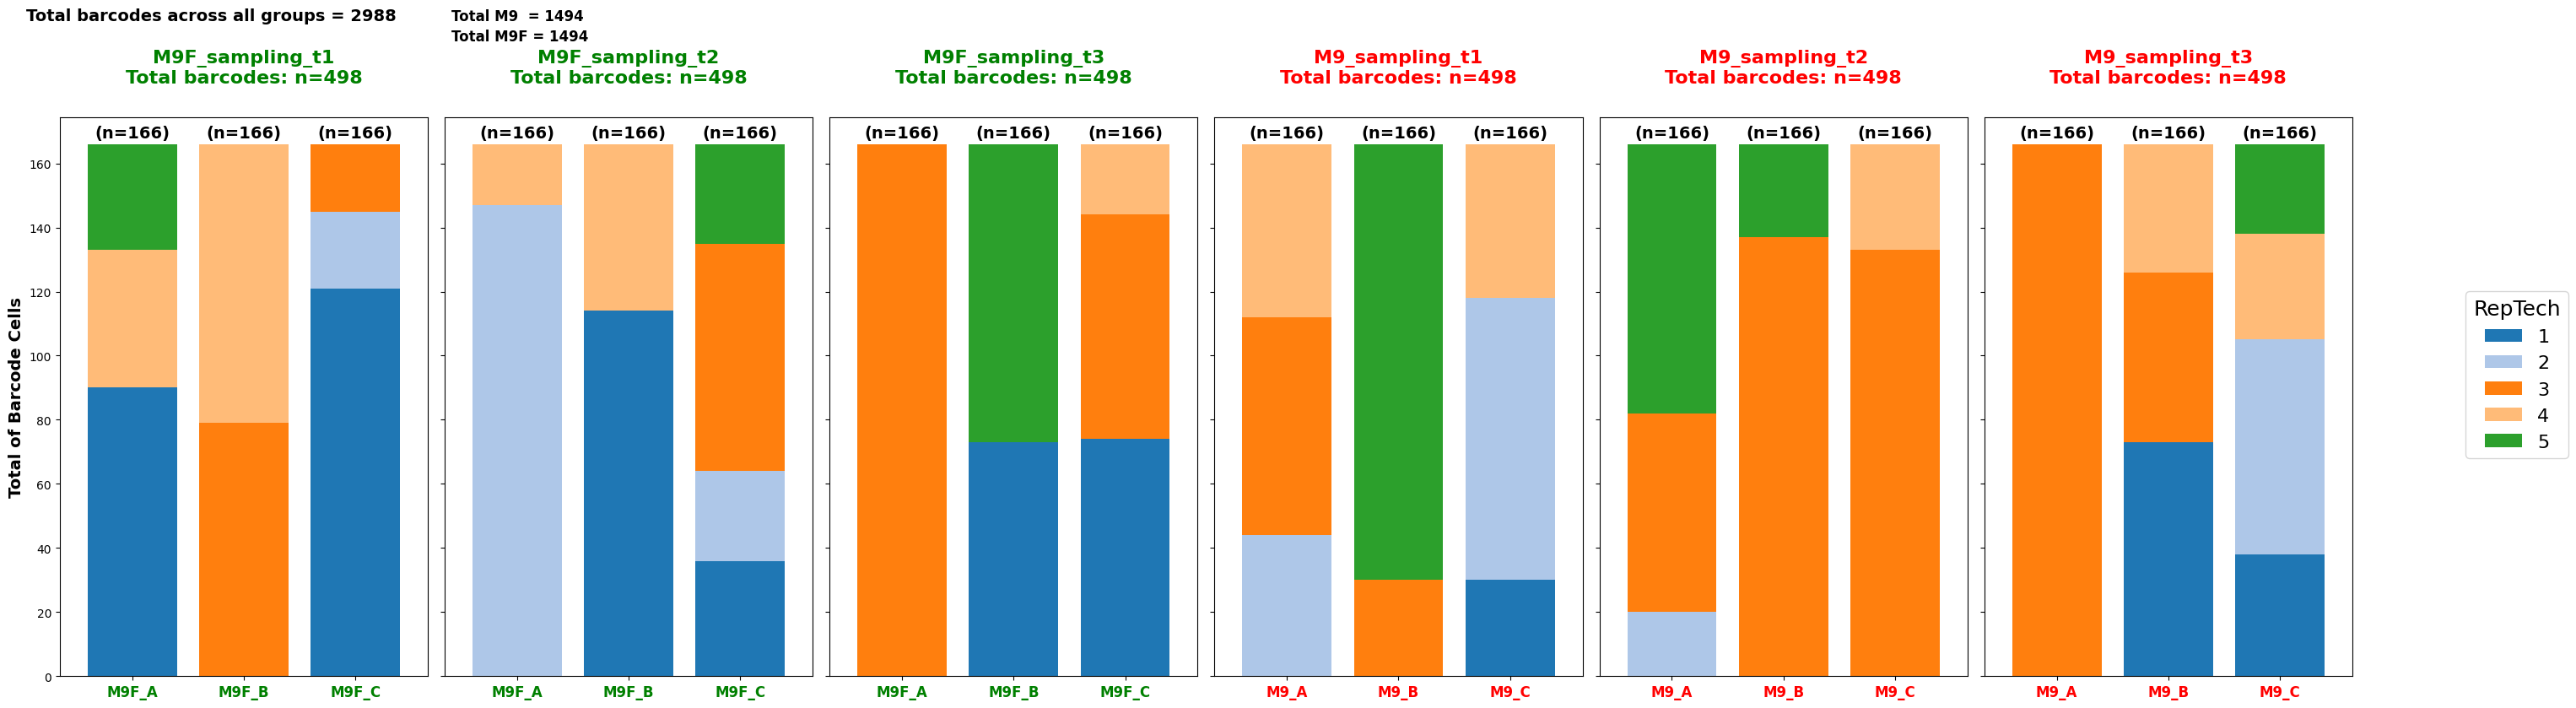

📊 Total cells: 2,988

📊 5.2 Generating violin + stripplot...


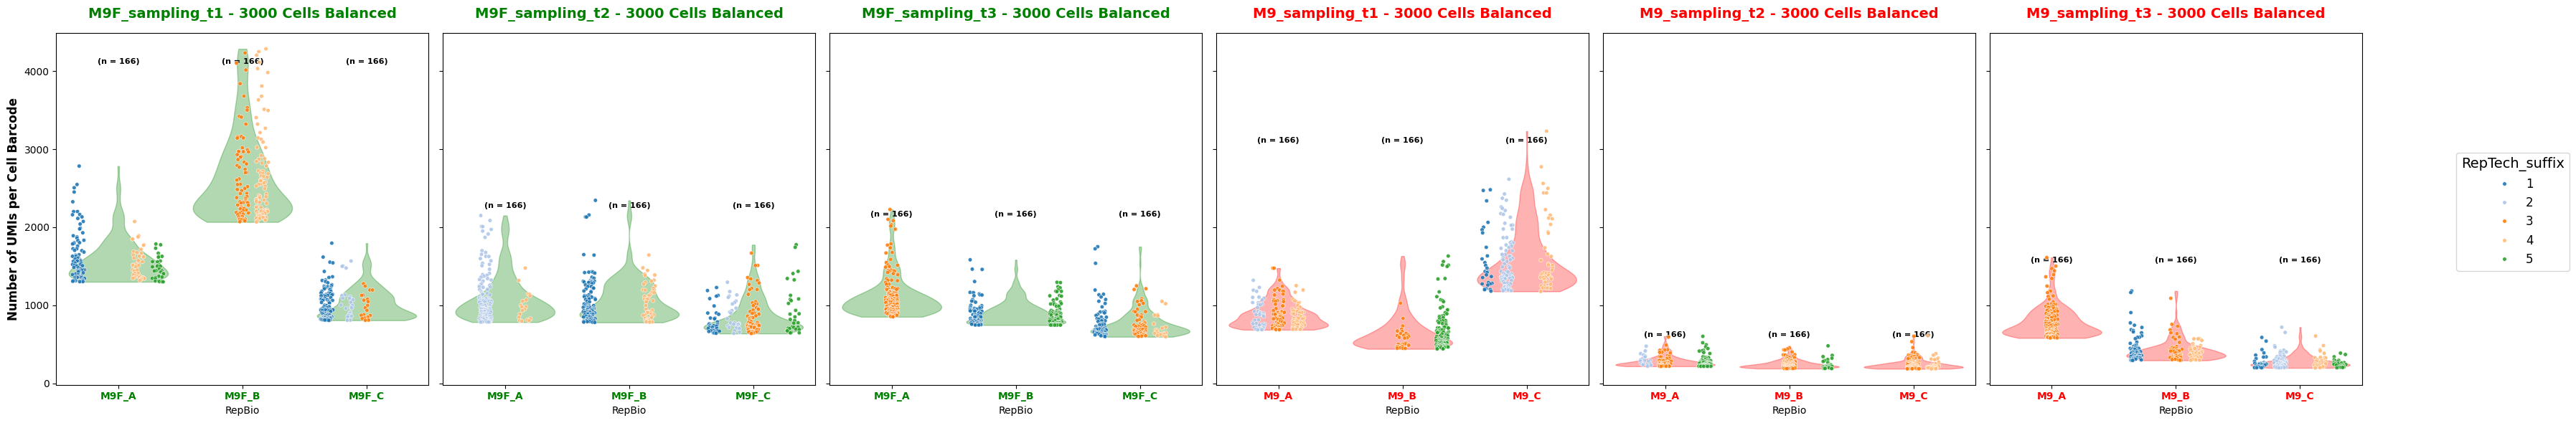

In [ ]:
# STEP 5: Balanced subsampling to 3000 cells
print("\n" + "=" * 80)
print("📊 STEP 5: BALANCED SUBSAMPLING TO 3000 CELLS")
print("=" * 80)

TARGET_CELLS_3000 = 3000

result = select_cells_by_group(
    adata=adata_filtered_100UMI_balanced_no_reptech_outliers,
    target_total_cells=TARGET_CELLS_3000,
    group_by="OD",
    sort_by="n_counts",
    random=False,
    seed=42,
    descending=True,
)

adata_filtered_100UMI_balanced_3000cells_by_OD = result["adata"]
print(f"✅ Subsampling to 3000 cells completed!")

# Stacked bar plot
print("\n📊 5.1 Generating stacked bar plot...")
total_all, total_by_medium = plot_stacked_bar_by_odt(
    adata_filtered_100UMI_balanced_3000cells_by_OD
)
print(f"📊 Total cells: {total_all:,}")

# Violin + stripplot
print("\n📊 5.2 Generating violin + stripplot...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_100UMI_balanced_3000cells_by_OD,
    y_column="n_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - 3000 Cells Balanced",
    figsize_per_plot=6,
)


📊 STEP 6: FINAL VISUALIZATIONS
📊 Final dataset: 2,988 cells

📊 6.1 Generating scatter comparison...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


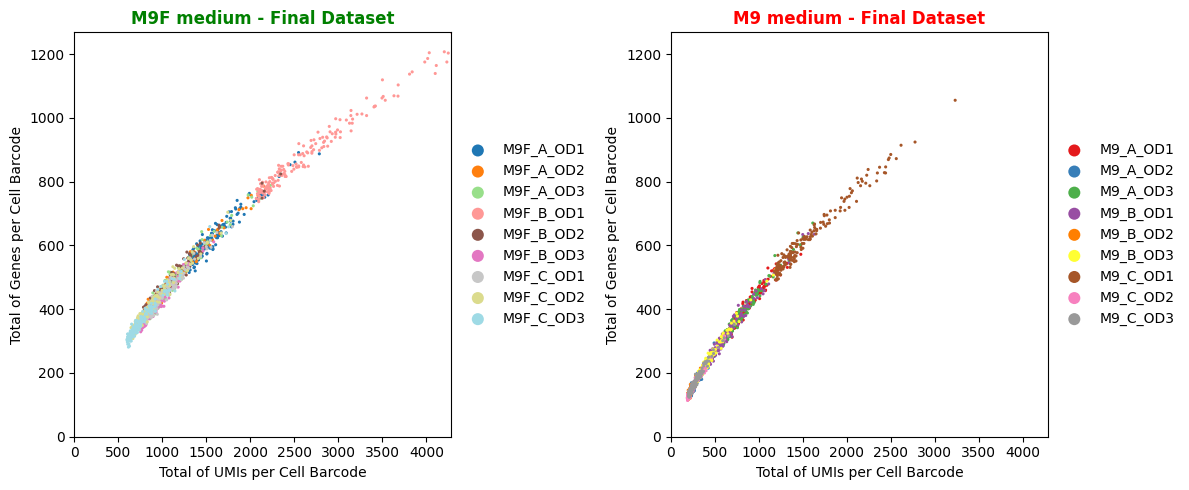


📊 6.2 Generating violin + stripplot...


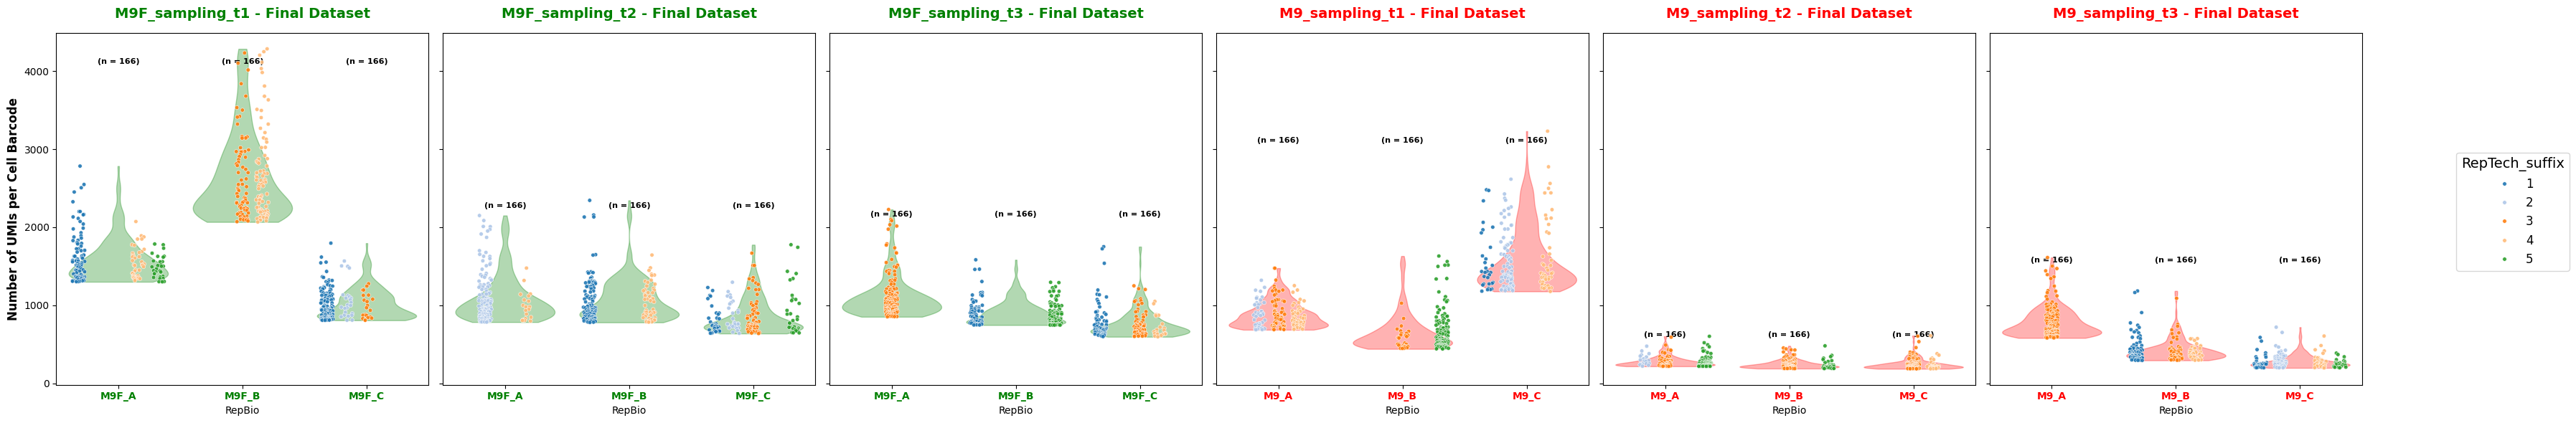


📊 6.3 Generating stacked bar plot...


/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:270: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(["group", "RepBio", "RepTech_suffix"])
/Users/valentingoupille/Internship_Val_Goupille_2025/code/Local_analysis/visualization_functions.py:405: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("CultureMedium")


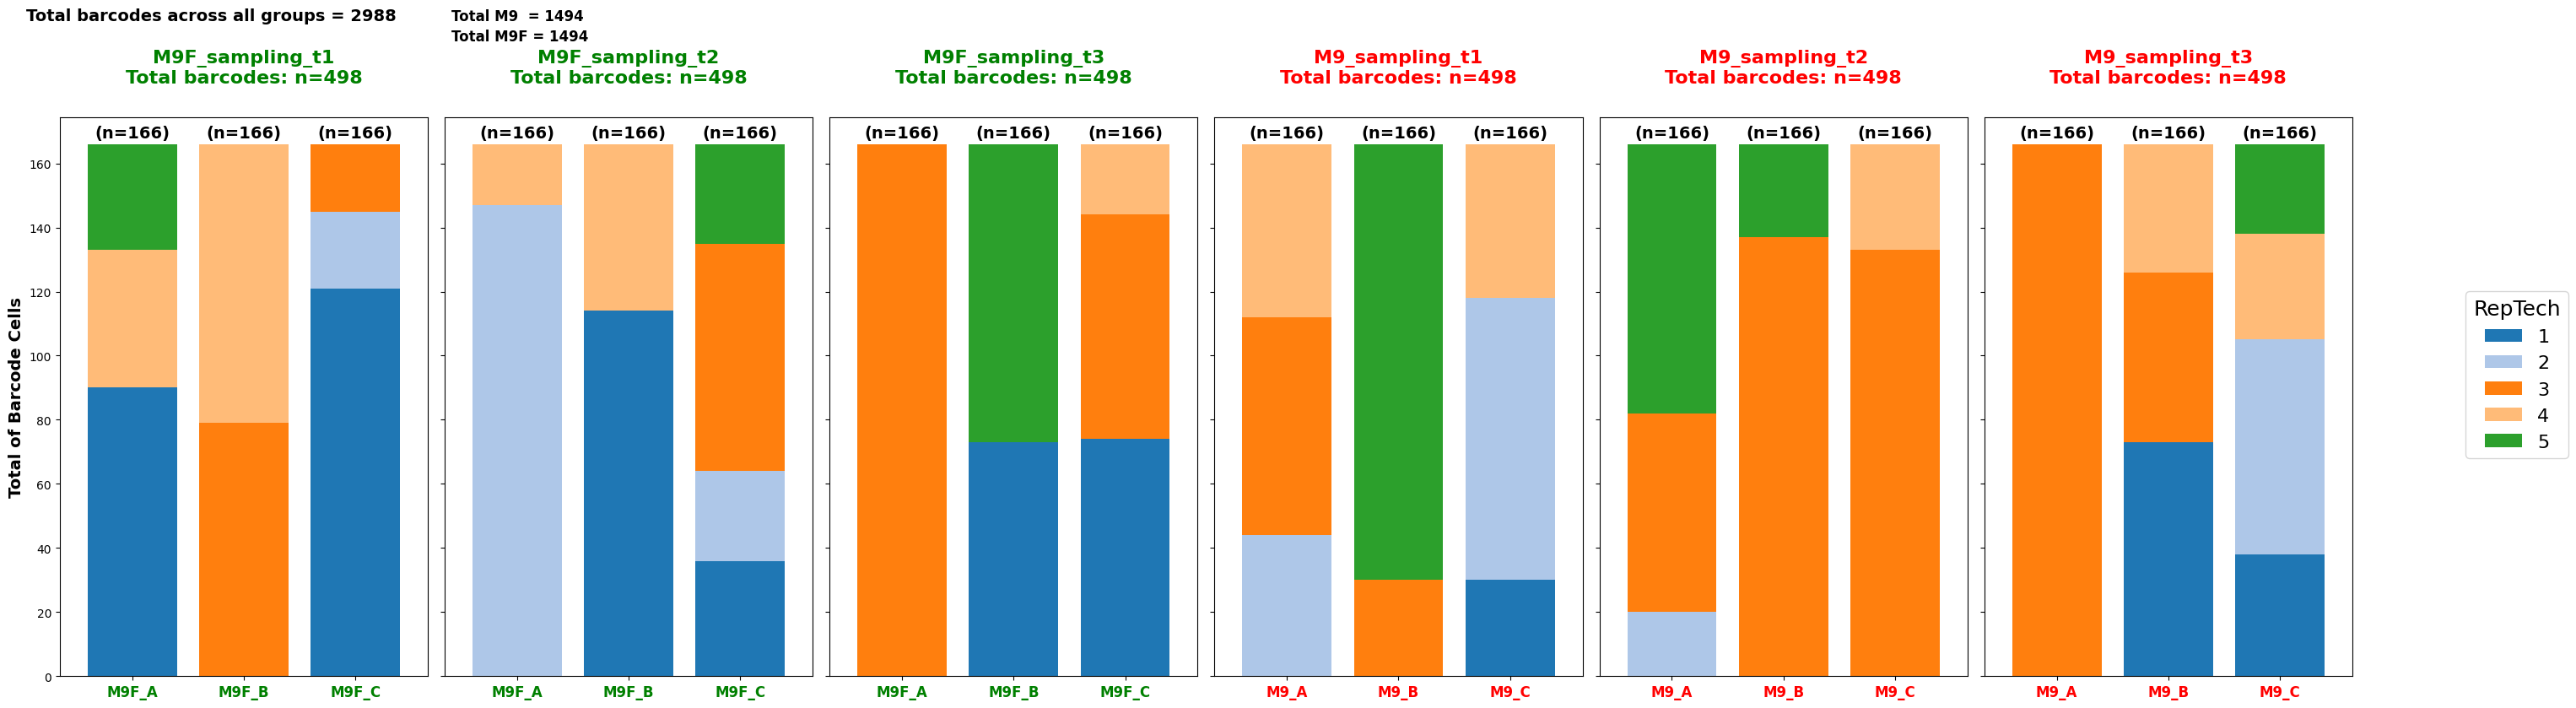

📊 Total cells: 2,988


In [ ]:
# STEP 6: Final visualizations
print("\n" + "=" * 80)
print("📊 STEP 6: FINAL VISUALIZATIONS")
print("=" * 80)

print(
    f"📊 Final dataset: {adata_filtered_100UMI_balanced_3000cells_by_OD.n_obs:,} cells"
)

# Use the 3000 cells dataset as final dataset
adata_filtered_100UMI_balanced_final = (
    adata_filtered_100UMI_balanced_3000cells_by_OD.copy()
)

# Scatter plot
print("\n📊 6.1 Generating scatter comparison...")
plot_scatter_comparison_m9f_m9(
    adata=adata_filtered_100UMI_balanced_final,
    x_column="n_counts",
    y_column="n_genes",
    color_column="OD",
    x_label="Total of UMIs per Cell Barcode",
    y_label="Total of Genes per Cell Barcode",
    title_suffix=" - Final Dataset",
    point_size=20,
    figsize=(12, 5),
    m9f_palette="tab20",
    m9_palette="Set1",
)

# Violin + stripplot
print("\n📊 6.2 Generating violin + stripplot...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_100UMI_balanced_final,
    y_column="n_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - Final Dataset",
    figsize_per_plot=6,
)

# Stacked bar plot
print("\n📊 6.3 Generating stacked bar plot...")
total_all, total_by_medium = plot_stacked_bar_by_odt(
    adata_filtered_100UMI_balanced_final
)
print(f"📊 Total cells: {total_all:,}")

In [ ]:
# Final summary of the filtering process
print("\n" + "=" * 80)
print("📊 FINAL SUMMARY OF V2 FILTERING PROCESS")
print("=" * 80)

filtering_summary = {
    "Step": [
        "1. Initial dataset (100UMI filtered)",
        "2. Balanced subsampling (4000 cells)",
        "3. RepTech filtering (≥20 cells)",
        "4. RepTech outlier removal",
        "5. Balanced subsampling (3000 cells)",
        "6. Final dataset",
    ],
    "n_cells": [
        adata_raw_filtered_100UMI.n_obs,
        adata_filtered_100UMI_balanced_4000cells_by_OD.n_obs,
        adata_filtered_100UMI_balanced_min20cells_per_RepTech.n_obs,
        adata_filtered_100UMI_balanced_no_reptech_outliers.n_obs,
        adata_filtered_100UMI_balanced_3000cells_by_OD.n_obs,
        adata_filtered_100UMI_balanced_final.n_obs,
    ],
    "n_genes": [
        adata_raw_filtered_100UMI.n_vars,
        adata_filtered_100UMI_balanced_4000cells_by_OD.n_vars,
        adata_filtered_100UMI_balanced_min20cells_per_RepTech.n_vars,
        adata_filtered_100UMI_balanced_no_reptech_outliers.n_vars,
        adata_filtered_100UMI_balanced_3000cells_by_OD.n_vars,
        adata_filtered_100UMI_balanced_final.n_vars,
    ],
}

summary_df = pd.DataFrame(filtering_summary)
summary_df["cells_removed"] = summary_df["n_cells"].diff().fillna(0) * -1
summary_df["cells_removed"] = summary_df["cells_removed"].astype(int)

print("\n📊 Filtering Summary Report:")
print("=" * 80)
print(summary_df.to_string(index=False))
print("=" * 80)

initial_cells = adata_raw_filtered_100UMI.n_obs
final_cells = adata_filtered_100UMI_balanced_final.n_obs
retention_percentage = (final_cells / initial_cells) * 100

print(f"\n📈 Overall Statistics:")
print(f"   Initial cells: {initial_cells:,}")
print(f"   Final cells: {final_cells:,}")
print(f"   Cells removed: {initial_cells - final_cells:,}")
print(f"   Retention rate: {retention_percentage:.1f}%")


📊 FINAL SUMMARY OF V2 FILTERING PROCESS

📊 Filtering Summary Report:
                                Step  n_cells  n_genes  cells_removed
1. Initial dataset (100UMI filtered)   132233     6248              0
2. Balanced subsampling (4000 cells)     3996     6248         128237
    3. RepTech filtering (≥20 cells)     3743     6248            253
          4. RepTech outlier removal     3714     6248             29
5. Balanced subsampling (3000 cells)     2988     6248            726
                    6. Final dataset     2988     6248              0

📈 Overall Statistics:
   Initial cells: 132,233
   Final cells: 2,988
   Cells removed: 129,245
   Retention rate: 2.3%


In [ ]:
# Save the final filtered dataset
print("\n💾 Saving final filtered dataset...")
OUTPUT_PATH = "data/Anndata/filtered"
OUTPUT_FILE = (
    "GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3b_v2.h5ad"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Save the final dataset
adata_filtered_100UMI_balanced_final.write_h5ad(os.path.join(OUTPUT_PATH, OUTPUT_FILE))

# Create CSV subdirectory for this step
csv_output_path = os.path.join(OUTPUT_PATH, "csv", "3b_filtering_advanced_cell")
os.makedirs(csv_output_path, exist_ok=True)

# Save summary report
summary_report_path = os.path.join(csv_output_path, "filtering_summary_report_v2.csv")
summary_df.to_csv(summary_report_path, index=False)

print(f"✅ Final dataset saved to: {os.path.join(OUTPUT_PATH, OUTPUT_FILE)}")
print(
    f"📊 Final dataset contains: {adata_filtered_100UMI_balanced_final.n_obs:,} cells × {adata_filtered_100UMI_balanced_final.n_vars:,} genes"
)

print("\n🎉 3b v2 Advanced cell filtering completed successfully!")


💾 Saving final filtered dataset...
✅ Final dataset saved to: data/Anndata/filtered/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3b_v2.h5ad
📊 Final dataset contains: 2,988 cells × 6,248 genes

🎉 3b v2 Advanced cell filtering completed successfully!
